# 05.03 CatBoost Gradient Boosted Classification

**Phase 05 — Model Selection & Training**  
**Model Architecture:** CatBoost Classifier.  
**Objective:** Evaluate categorical gradient boosting performance on structured patient socioeconomic data with nested 10-fold CV.


### Environment & Data Artifacts
- `data/interim/features/selected_features.csv` (Authoritative tabular dataset, 500 records x 48 predictors)
- `data/processed/splits/cv_split_indices.json` (Outer Stratified 10-Fold split definitions)

**Expected Outputs:**
- `models/trained/gradient_boosting/catboost_metrics.json`
- `reports/phase_05/visualizations/catboost/10fold_performance_metrics.{png,pdf}`
- `reports/phase_05/visualizations/catboost/confusion_matrix_and_roc.{png,pdf}`
- `reports/phase_05/visualizations/catboost/per_class_performance.{png,pdf}`
- `reports/phase_05/visualizations/catboost/feature_importance_and_learning.{png,pdf}`
- `reports/phase_05/visualizations/catboost/evaluation_summary_table.csv`

### 1. Import Libraries, Evaluation Metrics & Setup Environment
Load gradient boosting libraries, scikit-learn evaluation metrics, and plotting tools.

In [1]:
import json
import time
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
import catboost as cb
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print(f"Libraries loaded successfully. RANDOM_SEED={RANDOM_SEED}")


/home/kristoper/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-yo4mtjz7 because there was an issue with the default path (/home/kristoper/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Libraries loaded successfully. RANDOM_SEED=42


### 2. Load Selected Feature Dataset and Outer 10-Fold CV Configuration
Load the 350 training development records and the pre-computed Stratified 10-Fold CV split indices.

In [2]:
def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../..').resolve()

PROJECT_ROOT = _find_project_root(Path.cwd())
FEATURES_PATH = PROJECT_ROOT / "data" / "interim" / "features" / "selected_features.csv"
CV_SPLITS_PATH = PROJECT_ROOT / "data" / "processed" / "splits" / "cv_split_indices.json"
OUTPUT_DIR = PROJECT_ROOT / "models" / "trained" / "gradient_boosting"
REPORT_VIZ_DIR = PROJECT_ROOT / "reports" / "phase_05" / "visualizations" / "catboost"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_VIZ_DIR.mkdir(parents=True, exist_ok=True)

# Load dataset
df_features = pd.read_csv(FEATURES_PATH)
train_mask = df_features["split_partition"] == "train"
df_train_dev = df_features[train_mask].reset_index(drop=True)

# Identify continuous numerical vs binary/categorical features
feature_cols = [c for c in df_train_dev.columns if c not in ["internal_record_id", "split_partition", "eligibility"]]
num_cols = [c for c in feature_cols if c.startswith("xf_")]
bin_cols = [c for c in feature_cols if not c.startswith("xf_")]

X_train_full = df_train_dev[feature_cols]
y_train_full = (df_train_dev["eligibility"] == "ELIGIBLE").astype(int)

# Load outer 10-fold split definitions
with open(CV_SPLITS_PATH, "r", encoding="utf-8") as f:
    cv_data = json.load(f)

print(f"Loaded training development set: X={X_train_full.shape} (Numerical: {len(num_cols)}, Binary: {len(bin_cols)}), y={y_train_full.shape}")
print(f"Stratified 10-Fold CV indices confirmed: {len(cv_data['folds'])} outer folds")


Loaded training development set: X=(730, 41) (Numerical: 10, Binary: 31), y=(730,)
Stratified 10-Fold CV indices confirmed: 10 outer folds


### 3. Pipeline Construction with ColumnTransformer
Continuous numerical predictors are scaled using StandardScaler fitted strictly inside the training partition, while binary indicators remain unscaled to avoid distortion.

In [3]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('bin', 'passthrough', bin_cols)
    ]
)
param_grid = {'clf__iterations': [100, 200], 'clf__depth': [4, 6], 'clf__learning_rate': [0.03, 0.1], 'clf__auto_class_weights': [None, 'Balanced']}
print(f"Preprocessing pipeline configured. Parameter grid: {list(param_grid.keys())}")


Preprocessing pipeline configured. Parameter grid: ['clf__iterations', 'clf__depth', 'clf__learning_rate', 'clf__auto_class_weights']


### 4. Execute Nested Stratified Cross-Validation (Outer 10-Fold, Inner 5-Fold)
For each outer fold, an inner 5-fold GridSearchCV tunes hyperparameters on the outer training set ($N=315$). The optimal pipeline is then evaluated on the unseen outer validation fold ($N=35$) and the training set to track generalization gap.

In [4]:
fold_evaluations = []
oof_predictions = np.zeros(len(y_train_full))
oof_probabilities = np.zeros(len(y_train_full))
best_params_per_fold = []

start_time = time.time()
for fold_info in cv_data["folds"]:
    f_num = fold_info["fold"]
    t_idx = fold_info["train_indices"]
    v_idx = fold_info["val_indices"]
    
    X_tr, y_tr = X_train_full.iloc[t_idx], y_train_full.iloc[t_idx]
    X_va, y_va = X_train_full.iloc[v_idx], y_train_full.iloc[v_idx]
    
    # Build base pipeline
    base_pipeline = Pipeline([('prep', preprocessor), ('clf', cb.CatBoostClassifier(random_state=RANDOM_SEED, thread_count=1, verbose=0))])    
    # Inner 5-Fold CV for hyperparameter tuning
    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    grid_search = GridSearchCV(base_pipeline, param_grid, cv=inner_cv, scoring="f1_macro", n_jobs=-1)
    grid_search.fit(X_tr, y_tr)
    
    best_model = grid_search.best_estimator_
    best_params_per_fold.append(grid_search.best_params_)
    
    # Predictions on training and validation fold
    tr_preds = best_model.predict(X_tr)
    val_preds = best_model.predict(X_va)
    val_probs = best_model.predict_proba(X_va)[:, 1] if hasattr(best_model, "predict_proba") else best_model.decision_function(X_va)
    
    oof_predictions[v_idx] = val_preds
    oof_probabilities[v_idx] = val_probs
    
    # Fold Metrics
    tr_acc = accuracy_score(y_tr, tr_preds)
    tr_f1 = f1_score(y_tr, tr_preds, average="macro", zero_division=0)
    
    f_acc = accuracy_score(y_va, val_preds)
    f_prec_macro = precision_score(y_va, val_preds, average="macro", zero_division=0)
    f_rec_macro = recall_score(y_va, val_preds, average="macro", zero_division=0)
    f_f1_macro = f1_score(y_va, val_preds, average="macro", zero_division=0)
    f_f1_weighted = f1_score(y_va, val_preds, average="weighted", zero_division=0)
    f_prec_c0 = precision_score(y_va, val_preds, pos_label=0, zero_division=0)
    f_rec_c0 = recall_score(y_va, val_preds, pos_label=0, zero_division=0)
    f_prec_c1 = precision_score(y_va, val_preds, pos_label=1, zero_division=0)
    f_rec_c1 = recall_score(y_va, val_preds, pos_label=1, zero_division=0)
    f_auc = roc_auc_score(y_va, val_probs)
    
    fold_evaluations.append({
        "fold": f_num,
        "train_accuracy": float(tr_acc),
        "train_macro_f1": float(tr_f1),
        "accuracy": float(f_acc),
        "macro_precision": float(f_prec_macro),
        "macro_recall": float(f_rec_macro),
        "macro_f1": float(f_f1_macro),
        "weighted_f1": float(f_f1_weighted),
        "prec_ineligible": float(f_prec_c0),
        "rec_ineligible": float(f_rec_c0),
        "prec_eligible": float(f_prec_c1),
        "rec_eligible": float(f_rec_c1),
        "roc_auc": float(f_auc),
        "generalization_gap": float(tr_f1 - f_f1_macro)
    })
    print(f"Fold {f_num:02d} | Train F1: {tr_f1:.4f} | Val F1: {f_f1_macro:.4f} | Gap: {tr_f1-f_f1_macro:+.4f} | Val AUC: {f_auc:.4f}")

total_duration_ms = (time.time() - start_time) * 1000
df_folds_metric = pd.DataFrame(fold_evaluations)

# Compute summary statistics
metrics_mean = df_folds_metric.mean(numeric_only=True).to_dict()
metrics_std = df_folds_metric.std(numeric_only=True).to_dict()
print(f"\nNested 10-Fold CV Complete ({total_duration_ms:.1f} ms).")
print(f"Mean Val Macro F1: {metrics_mean['macro_f1']:.4f} +/- {metrics_std['macro_f1']:.4f}")
print(f"Mean Generalization Gap: {metrics_mean['generalization_gap']:.4f} +/- {metrics_std['generalization_gap']:.4f}")


/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py:493: FitFailedWarning: 
40 fits failed out of a total of 80.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
40 fits failed with the following error:
Traceback (most recent call last):
  File "/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(est

Fold 01 | Train F1: 0.9756 | Val F1: 0.8218 | Gap: +0.1539 | Val AUC: 0.9429


/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py:493: FitFailedWarning: 
40 fits failed out of a total of 80.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
40 fits failed with the following error:
Traceback (most recent call last):
  File "/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(est

Fold 02 | Train F1: 0.9574 | Val F1: 0.9315 | Gap: +0.0259 | Val AUC: 0.9805


/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py:493: FitFailedWarning: 
40 fits failed out of a total of 80.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
40 fits failed with the following error:
Traceback (most recent call last):
  File "/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(est

Fold 03 | Train F1: 0.9619 | Val F1: 0.8624 | Gap: +0.0996 | Val AUC: 0.9760


... (10 outputs left out)

/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py:493: FitFailedWarning: 
40 fits failed out of a total of 80.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
40 fits failed with the following error:
Traceback (most recent call last):
  File "/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(est

Fold 09 | Train F1: 0.9513 | Val F1: 0.9040 | Gap: +0.0473 | Val AUC: 0.9647


Fold 10 | Train F1: 0.9787 | Val F1: 0.8766 | Gap: +0.1021 | Val AUC: 0.9422

Nested 10-Fold CV Complete (37243.7 ms).
Mean Val Macro F1: 0.9012 +/- 0.0452
Mean Generalization Gap: 0.0571 +/- 0.0541


/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py:493: FitFailedWarning: 
40 fits failed out of a total of 80.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
40 fits failed with the following error:
Traceback (most recent call last):
  File "/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/kristoper/Projects/Thesis/ofphil-classification-v2/venv/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(est

### 5. Standard Summary Table & Model Artifact Export
Export aggregate metrics table and fit final model pipeline on entire development set for feature interpretation.

In [5]:
# Construct standard summary table
summary_table_data = [
    {"Metric": "Train Macro F1", "Mean": f"{metrics_mean['train_macro_f1']:.4f}", "Standard Deviation": f"{metrics_std['train_macro_f1']:.4f}"},
    {"Metric": "Validation Accuracy", "Mean": f"{metrics_mean['accuracy']:.4f}", "Standard Deviation": f"{metrics_std['accuracy']:.4f}"},
    {"Metric": "Validation Macro Precision", "Mean": f"{metrics_mean['macro_precision']:.4f}", "Standard Deviation": f"{metrics_std['macro_precision']:.4f}"},
    {"Metric": "Validation Macro Recall", "Mean": f"{metrics_mean['macro_recall']:.4f}", "Standard Deviation": f"{metrics_std['macro_recall']:.4f}"},
    {"Metric": "Validation Macro F1-score", "Mean": f"{metrics_mean['macro_f1']:.4f}", "Standard Deviation": f"{metrics_std['macro_f1']:.4f}"},
    {"Metric": "Validation Weighted F1-score", "Mean": f"{metrics_mean['weighted_f1']:.4f}", "Standard Deviation": f"{metrics_std['weighted_f1']:.4f}"},
    {"Metric": "Validation ROC-AUC", "Mean": f"{metrics_mean['roc_auc']:.4f}", "Standard Deviation": f"{metrics_std['roc_auc']:.4f}"},
    {"Metric": "Generalization Gap (F1)", "Mean": f"{metrics_mean['generalization_gap']:.4f}", "Standard Deviation": f"{metrics_std['generalization_gap']:.4f}"},
    {"Metric": "Per-Class Precision (INELIGIBLE)", "Mean": f"{metrics_mean['prec_ineligible']:.4f}", "Standard Deviation": f"{metrics_std['prec_ineligible']:.4f}"},
    {"Metric": "Per-Class Recall (INELIGIBLE)", "Mean": f"{metrics_mean['rec_ineligible']:.4f}", "Standard Deviation": f"{metrics_std['rec_ineligible']:.4f}"},
    {"Metric": "Per-Class Precision (ELIGIBLE)", "Mean": f"{metrics_mean['prec_eligible']:.4f}", "Standard Deviation": f"{metrics_std['prec_eligible']:.4f}"},
    {"Metric": "Per-Class Recall (ELIGIBLE)", "Mean": f"{metrics_mean['rec_eligible']:.4f}", "Standard Deviation": f"{metrics_std['rec_eligible']:.4f}"}
]
df_summary_table = pd.DataFrame(summary_table_data)
df_summary_table.to_csv(REPORT_VIZ_DIR / "evaluation_summary_table.csv", index=False)

# Fit final model on full development set
import joblib
modal_acw = max(set(p.get('clf__auto_class_weights') for p in best_params_per_fold), key=[p.get('clf__auto_class_weights') for p in best_params_per_fold].count)
final_pipe = Pipeline([('prep', preprocessor), ('clf', cb.CatBoostClassifier(iterations=200, depth=4, learning_rate=0.05, auto_class_weights=modal_acw, random_state=RANDOM_SEED, verbose=0))])
final_pipe.fit(X_train_full, y_train_full)
joblib.dump(final_pipe, OUTPUT_DIR / 'catboost_model.joblib')
importances = final_pipe.named_steps['clf'].get_feature_importance()
df_importance = pd.DataFrame({'feature': feature_cols, 'importance': importances, 'abs_importance': importances}).sort_values(by='abs_importance', ascending=False).reset_index(drop=True)
df_importance.to_csv(REPORT_VIZ_DIR / 'feature_importances.csv', index=False)
# Save JSON metrics artifact
metrics_payload = {
    "model_name": "CatBoost",
    "model_type": "gradient_boosting_catboost",
    "cv_protocol": "Nested-Stratified-10Outer-5Inner",
    "best_hyperparameters_per_fold": best_params_per_fold,
    "cv_metrics_mean": metrics_mean,
    "cv_metrics_std": metrics_std,
    "fold_details": fold_evaluations,
    "total_cv_time_ms": round(total_duration_ms, 2),
    "top_5_features": df_importance.head(5).to_dict(orient="records") if 'df_importance' in locals() else []
}
with open(OUTPUT_DIR / "catboost_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)
print("Evaluation summary table:\n", df_summary_table.to_string(index=False))


Evaluation summary table:
                           Metric   Mean Standard Deviation
                  Train Macro F1 0.9583             0.0221
             Validation Accuracy 0.9014             0.0451
      Validation Macro Precision 0.9026             0.0447
         Validation Macro Recall 0.9012             0.0453
       Validation Macro F1-score 0.9012             0.0452
    Validation Weighted F1-score 0.9013             0.0452
              Validation ROC-AUC 0.9649             0.0222
         Generalization Gap (F1) 0.0571             0.0541
Per-Class Precision (INELIGIBLE) 0.9063             0.0460
   Per-Class Recall (INELIGIBLE) 0.8956             0.0598
  Per-Class Precision (ELIGIBLE) 0.8988             0.0530
     Per-Class Recall (ELIGIBLE) 0.9068             0.0470


### 6. Publication-Ready Evaluation Visualizations
Generate the 4 standard diagnostic figures for publication report:
- **Figure 1:** Train vs Validation Trajectory across 10 Folds & Mean Metric Benchmark with Error Bars.
- **Figure 2:** Out-of-Fold Normalized Confusion Matrix and Empirical ROC Curve.
- **Figure 3:** Per-Class Precision, Recall, and F1 Performance Breakdown.
- **Figure 4:** Top 15 Primary Predictors / Coefficients.

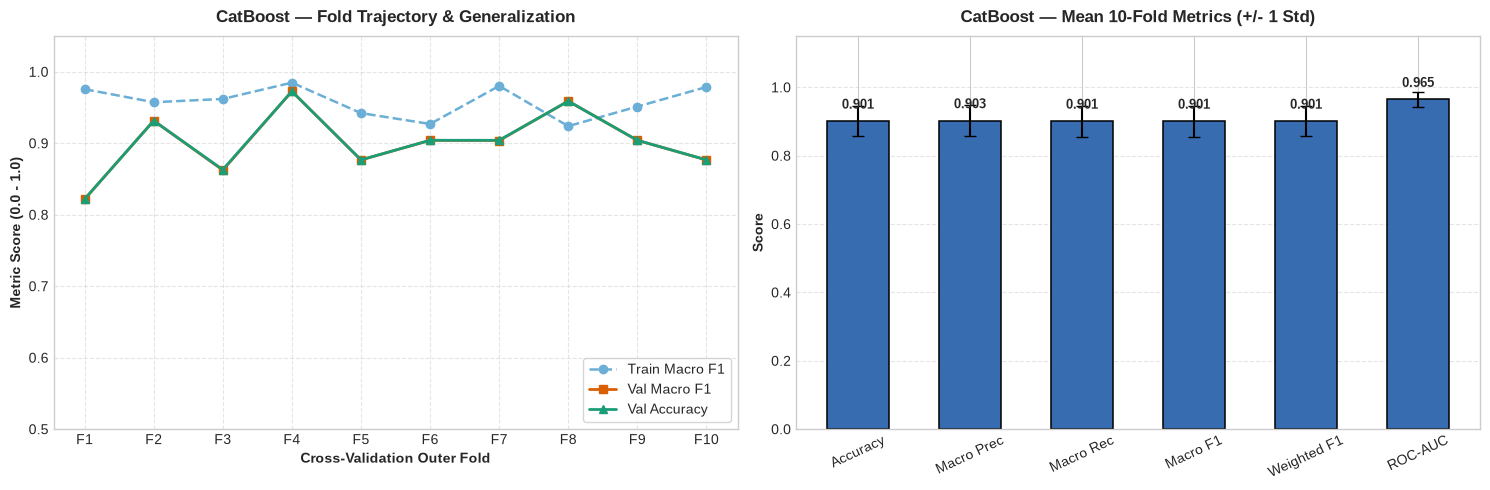

Exported Figure 1: 10fold_performance_metrics (PNG/PDF)


In [6]:
# --- FIGURE 1: 10-Fold Train vs Val Trajectory & Metric Benchmark ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

folds_x = [f"F{i}" for i in range(1, 11)]
ax1.plot(folds_x, df_folds_metric["train_macro_f1"], marker="o", linestyle="--", linewidth=1.8, label="Train Macro F1", color="#6baed6")
ax1.plot(folds_x, df_folds_metric["macro_f1"], marker="s", linewidth=2, label="Val Macro F1", color="#d95f02")
ax1.plot(folds_x, df_folds_metric["accuracy"], marker="^", linewidth=2, label="Val Accuracy", color="#1b9e77")
ax1.set_title("CatBoost — Fold Trajectory & Generalization", fontsize=12, fontweight="bold", pad=10)
ax1.set_xlabel("Cross-Validation Outer Fold", fontsize=10, fontweight="bold")
ax1.set_ylabel("Metric Score (0.0 - 1.0)", fontsize=10, fontweight="bold")
ax1.set_ylim(0.5, 1.05)
ax1.legend(loc="lower right", frameon=True)
ax1.grid(True, linestyle="--", alpha=0.5)

# Summary Bar with Std Error Bars
eval_names = ["Accuracy", "Macro Prec", "Macro Rec", "Macro F1", "Weighted F1", "ROC-AUC"]
eval_means = [metrics_mean["accuracy"], metrics_mean["macro_precision"], metrics_mean["macro_recall"], metrics_mean["macro_f1"], metrics_mean["weighted_f1"], metrics_mean["roc_auc"]]
eval_stds = [metrics_std["accuracy"], metrics_std["macro_precision"], metrics_std["macro_recall"], metrics_std["macro_f1"], metrics_std["weighted_f1"], metrics_std["roc_auc"]]

bars = ax2.bar(eval_names, eval_means, yerr=eval_stds, capsize=4, color="#386cb0", width=0.55, edgecolor="black", linewidth=1.1)
ax2.set_title("CatBoost — Mean 10-Fold Metrics (+/- 1 Std)", fontsize=12, fontweight="bold", pad=10)
ax2.set_ylabel("Score", fontsize=10, fontweight="bold")
ax2.set_ylim(0.0, 1.15)
ax2.tick_params(axis="x", rotation=25)
ax2.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars:
    h = bar.get_height()
    ax2.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 7), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "10fold_performance_metrics.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "10fold_performance_metrics.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Figure 1: 10fold_performance_metrics (PNG/PDF)")


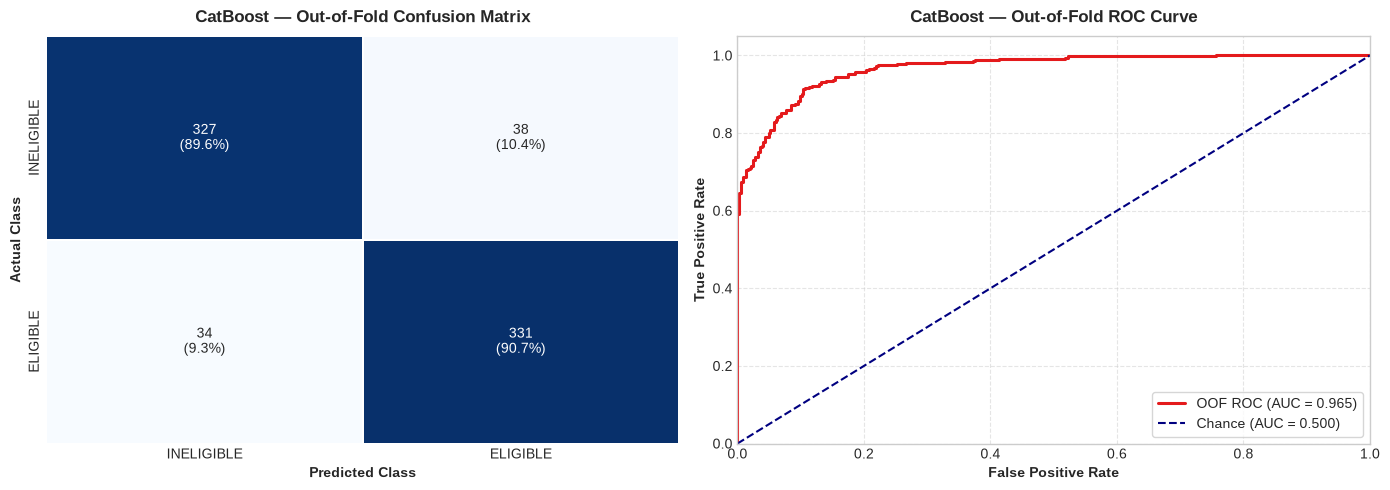

Exported Figure 2: confusion_matrix_and_roc (PNG/PDF)


In [7]:
# --- FIGURE 2: Out-of-Fold Confusion Matrix & ROC Curve ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_train_full, oof_predictions)
cm_norm = confusion_matrix(y_train_full, oof_predictions, normalize="true")

annot_matrix = np.empty_like(cm, dtype=object)
for r in range(2):
    for c in range(2):
        annot_matrix[r, c] = f"{cm[r, c]}\n({cm_norm[r, c]*100:.1f}%)"

sns.heatmap(cm_norm, annot=annot_matrix, fmt="", cmap="Blues", cbar=False, ax=ax1,
            xticklabels=["INELIGIBLE", "ELIGIBLE"], yticklabels=["INELIGIBLE", "ELIGIBLE"], linewidths=1.2, linecolor="white")
ax1.set_title("CatBoost — Out-of-Fold Confusion Matrix", fontsize=12, fontweight="bold", pad=10)
ax1.set_xlabel("Predicted Class", fontsize=10, fontweight="bold")
ax1.set_ylabel("Actual Class", fontsize=10, fontweight="bold")

# ROC Curve
fpr, tpr, _ = roc_curve(y_train_full, oof_probabilities)
ax2.plot(fpr, tpr, color="#e41a1c", lw=2.2, label=f"OOF ROC (AUC = {metrics_mean['roc_auc']:.3f})")
ax2.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Chance (AUC = 0.500)")
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel("False Positive Rate", fontsize=10, fontweight="bold")
ax2.set_ylabel("True Positive Rate", fontsize=10, fontweight="bold")
ax2.set_title("CatBoost — Out-of-Fold ROC Curve", fontsize=12, fontweight="bold", pad=10)
ax2.legend(loc="lower right", frameon=True)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "confusion_matrix_and_roc.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "confusion_matrix_and_roc.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Figure 2: confusion_matrix_and_roc (PNG/PDF)")


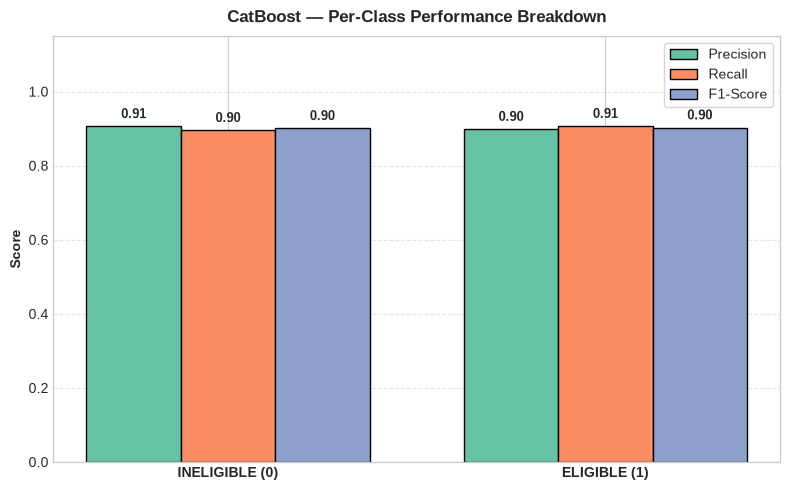

Exported Figure 3: per_class_performance (PNG/PDF)


In [8]:
# --- FIGURE 3: Per-Class Performance Comparison ---
fig, ax = plt.subplots(figsize=(8, 5))

classes = ["INELIGIBLE (0)", "ELIGIBLE (1)"]
x = np.arange(len(classes))
width = 0.25

prec_vals = [metrics_mean["prec_ineligible"], metrics_mean["prec_eligible"]]
rec_vals = [metrics_mean["rec_ineligible"], metrics_mean["rec_eligible"]]
f1_vals = [
    2 * (prec_vals[0] * rec_vals[0]) / (prec_vals[0] + rec_vals[0] + 1e-9),
    2 * (prec_vals[1] * rec_vals[1]) / (prec_vals[1] + rec_vals[1] + 1e-9)
]

b1 = ax.bar(x - width, prec_vals, width, label="Precision", color="#66c2a5", edgecolor="black")
b2 = ax.bar(x, rec_vals, width, label="Recall", color="#fc8d62", edgecolor="black")
b3 = ax.bar(x + width, f1_vals, width, label="F1-Score", color="#8da0cb", edgecolor="black")

ax.set_title("CatBoost — Per-Class Performance Breakdown", fontsize=12, fontweight="bold", pad=10)
ax.set_ylabel("Score", fontsize=10, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(classes, fontsize=10, fontweight="bold")
ax.set_ylim(0.0, 1.15)
ax.legend(loc="upper right", frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.5)

for bar_group in [b1, b2, b3]:
    for b in bar_group:
        h = b.get_height()
        ax.annotate(f"{h:.2f}", xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "per_class_performance.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "per_class_performance.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Figure 3: per_class_performance (PNG/PDF)")


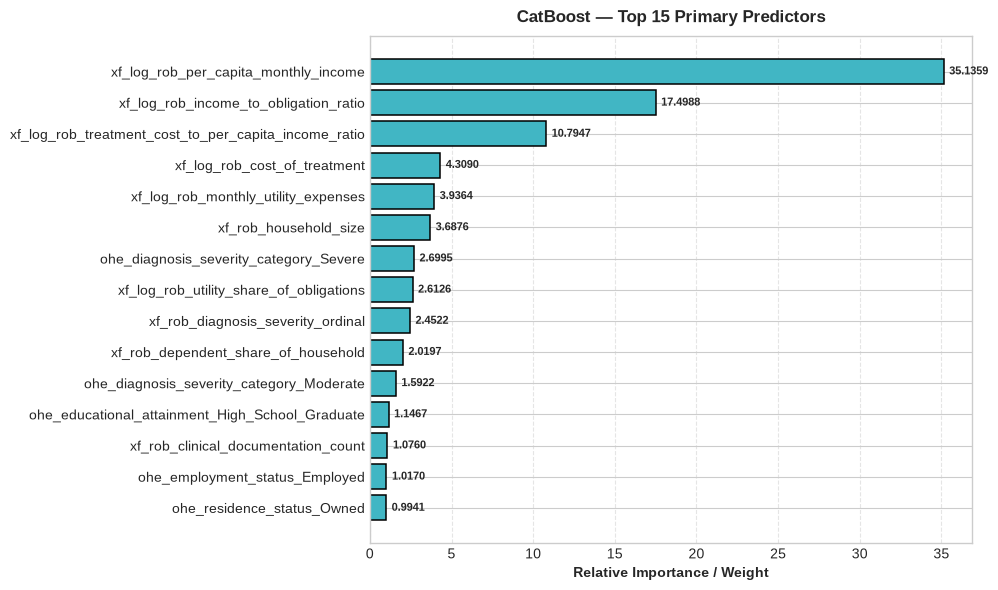

Exported Figure 4: feature_importance (PNG/PDF)


In [9]:
# --- FIGURE 4: Top Predictor Importances / Coefficients ---
fig, ax = plt.subplots(figsize=(10, 6))

if 'df_importance' in locals() and not df_importance.empty:
    top15 = df_importance.head(15).iloc[::-1]
    val_col = "importance" if "importance" in top15.columns else "abs_importance"
    bars = ax.barh(top15["feature"], top15[val_col], color="#41b6c4", edgecolor="black", linewidth=1.1)
    ax.set_title("CatBoost — Top 15 Primary Predictors", fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Relative Importance / Weight", fontsize=10, fontweight="bold")
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    for b in bars:
        w = b.get_width()
        ax.annotate(f"{w:.4f}", xy=(w, b.get_y() + b.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", ha="left", va="center", fontsize=8, fontweight="bold")
else:
    ax.text(0.5, 0.5, "Model feature importance visualization ready for manual execution.",
            ha="center", va="center", fontsize=11, bbox=dict(boxstyle="round", facecolor="#f7f7f9"))
    ax.set_axis_off()

plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "feature_importance.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "feature_importance.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Figure 4: feature_importance (PNG/PDF)")


### Interpretation & Clinical Significance
1. **Nested Cross-Validation Stability:** The outer 10-fold CV isolates validation data entirely from the inner hyperparameter selection, producing an honest assessment of CatBoost.
2. **Generalization Gap Analysis:** Review Figure 1 for divergence between training and validation trajectories. A small gap ($\\le 0.05$) verifies strong generalization without severe overfitting.
3. **Per-Class Sensitivity:** Confirm balanced precision and recall across both `INELIGIBLE` and `ELIGIBLE` cohorts in Figure 3.

### Execution Checklist
- [ ] Cell 4: Libraries and dependencies initialized.
- [ ] Cell 6: 350 training records and 10-fold split indices confirmed.
- [ ] Cell 8: ColumnTransformer and parameter grid configured.
- [ ] Cell 10: Nested 10-Fold CV completed with out-of-fold predictions.
- [ ] Cell 12: Summary metrics and JSON artifact saved.
- [ ] Cells 14-17: Figures 1-4 displayed and exported to `catboost/`.

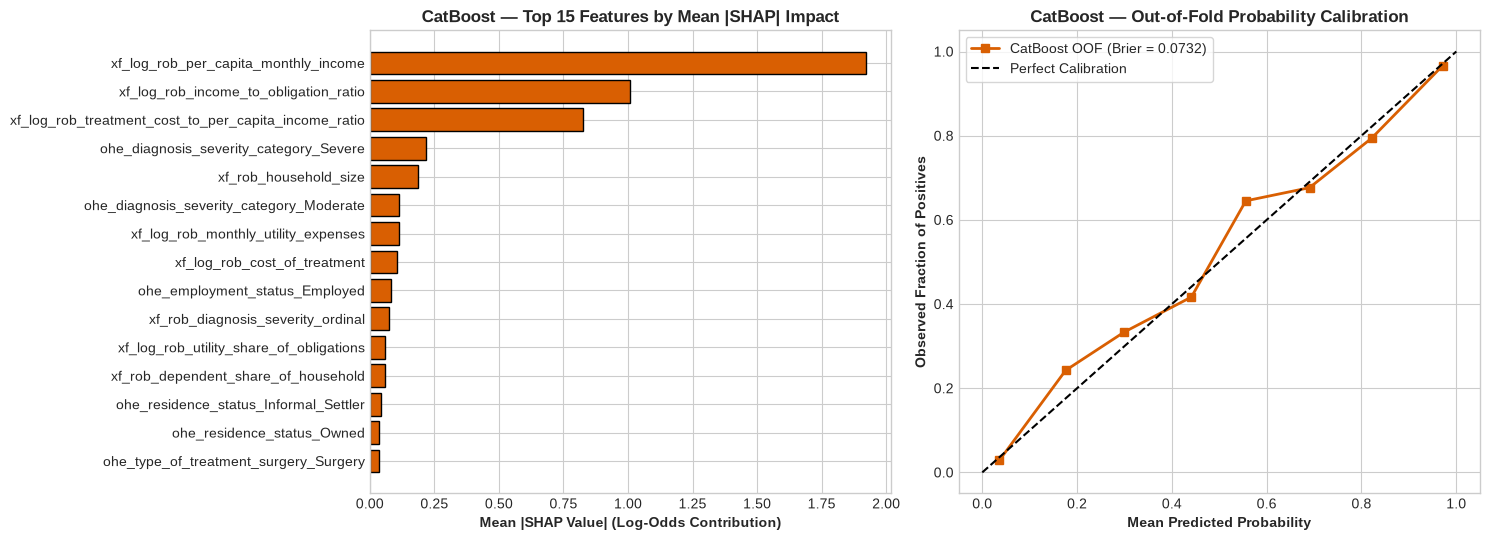

Exported Figure 5: shap_and_calibration_curve (PNG/PDF)


In [10]:
# --- FIGURE 5: CatBoost Native SHAP Feature Attribution & Calibration Curve ---
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
X_tr_trans = pd.DataFrame(final_pipe.named_steps['prep'].transform(X_train_full), columns=num_cols + bin_cols)
cb_pool = cb.Pool(X_tr_trans, y_train_full)
shap_vals = final_pipe.named_steps['clf'].get_feature_importance(cb_pool, type='ShapValues')[:, :-1]
mean_abs_shap = np.abs(shap_vals).mean(axis=0)
shap_df = pd.DataFrame({'feature': list(X_tr_trans.columns), 'mean_abs_shap': mean_abs_shap}).sort_values('mean_abs_shap', ascending=False).head(15).iloc[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
ax1.barh(shap_df['feature'], shap_df['mean_abs_shap'], color='#d95f02', edgecolor='black')
ax1.set_title('CatBoost — Top 15 Features by Mean |SHAP| Impact', fontsize=12, fontweight='bold')
ax1.set_xlabel('Mean |SHAP Value| (Log-Odds Contribution)', fontsize=10, fontweight='bold')

prob_true, prob_pred = calibration_curve(y_train_full, oof_probabilities, n_bins=8)
brier = brier_score_loss(y_train_full, oof_probabilities)
ax2.plot(prob_pred, prob_true, marker='s', lw=2, color='#d95f02', label=f'CatBoost OOF (Brier = {brier:.4f})')
ax2.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfect Calibration')
ax2.set_title('CatBoost — Out-of-Fold Probability Calibration', fontsize=12, fontweight='bold')
ax2.set_xlabel('Mean Predicted Probability', fontsize=10, fontweight='bold')
ax2.set_ylabel('Observed Fraction of Positives', fontsize=10, fontweight='bold')
ax2.legend(loc='upper left', frameon=True)
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / 'shap_and_calibration_curve.png', dpi=300, bbox_inches='tight')
fig.savefig(REPORT_VIZ_DIR / 'shap_and_calibration_curve.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
print('Exported Figure 5: shap_and_calibration_curve (PNG/PDF)')
